# Storyline 2: After staffing increases, do completions and backlog improve?

**Core question: Are completion increases and total-backlog reductions more common in staffing-increase years than in other years? Does this difference persist when receipt growth is similar?**

FY2008–FY2025 | Top ten agencies by observed cumulative requests received

Personnel uses type 22 total FTE; completions and receipts use type 01; backlog consistently uses type 26 as reported for that year. Only agency-overall rows are used. Missing and negative values are not filled with zero. Ratios require valid nonzero denominators; annual changes require consecutive years. Historical reports may differ in measurement, and calculations use the original reported values.

The only input is `component_master_no_03_06_11.csv`. No costs are analyzed, so CPI is not needed. Comparisons describe same-year changes and provide evidence about staffing and performance without presuming a beneficial staffing effect.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
plt.rcParams.update({'font.sans-serif': ['DejaVu Sans'], 'axes.unicode_minus': False, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.2, 'font.size': 10})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 200)
data_directories = [Path('.'), Path('fa26/storyline'), Path('storyline')]
ROOT = next((p for p in data_directories if (p / 'component_master_no_03_06_11.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Keep the two CSV files beside the notebooks, or run from the repository root.')
SOURCE = ROOT / 'component_master_no_03_06_11.csv'
CPI = ROOT / 'cpi_u_bls_monthly_2007_2025.csv'
raw = pd.read_csv(SOURCE, dtype=str, keep_default_na=False)
fields = {'fte': '22_Personnel__TotalFullTimeStaffQuantity', 'fulltime': '22_Personnel__FullTimeEmployeeQuantity', 'equivalent': '22_Personnel__EquivalentFullTimeEmployeeQuantity', 'cost': '23_Costs__ProcessingCostAmount', 'total': '23_Costs__TotalCostAmount', 'litigation': '23_Costs__LitigationCostAmount', 'received': '01_Requests__ProcessingStatisticsReceivedQuantity', 'processed': '01_Requests__ProcessingStatisticsProcessedQuantity', 'backlog': '26_Backlog__BackloggedRequestQuantity', 'pending': '01_Requests__ProcessingStatisticsPendingAtEndQuantity', 'backlog_current_comparison': '30_ComparisonsRequestsBacklogged__BacklogCurrentYearQuantity', 'backlog_previous_comparison': '30_ComparisonsRequestsBacklogged__BacklogLastYearQuantity'}
labels = {'fte': 'Total FTE', 'fulltime': 'Full-time employees', 'equivalent': 'Equivalent FTE', 'cost': 'Nominal processing cost', 'total': 'Nominal total cost', 'litigation': 'Nominal litigation cost', 'received': 'Requests received', 'processed': 'Requests processed', 'backlog': 'Request backlog', 'pending': 'Pending requests', 'backlog_current_comparison': 'Current-year backlog in same report', 'backlog_previous_comparison': 'Prior-year backlog in same report', 'agency': 'Agency', 'year': 'Fiscal year'}
a = raw[raw['Row Type'].eq('agency_overall') & ~raw['Exclude From Component Sum'].str.strip().str.lower().eq('yes')].copy()
a['agency'] = a['Agency Abbreviation'].str.strip()
a['year'] = pd.to_numeric(a['Fiscal Year'], errors='raise').astype(int)
assert not a.duplicated(['agency', 'year']).any()
for short, col in fields.items():
    v = pd.to_numeric(a[col], errors='coerce')
    a[short] = v.mask(v.lt(0))
a = a.sort_values(['agency', 'year']).reset_index(drop=True)
ranking = a.groupby('agency').received.sum(min_count=1).sort_values(ascending=False)
TOP = ranking.head(10).index.tolist()
names = {'DHS': 'Homeland Security', 'DOJ': 'Justice', 'DoD': 'Defense', 'HHS': 'Health and Human Services', 'VA': 'Veterans Affairs', 'NARA': 'National Archives', 'SSA': 'Social Security Administration', 'USDA': 'Agriculture', 'DOL': 'Labor', 'DOS': 'State'}
colors = {ag: plt.cm.tab10(i) for i, ag in enumerate(TOP)}

def table(frame, mapping=None, digits=3):
    display(frame.rename(columns=mapping or {}).round(digits))

def finish(fig):
    fig.tight_layout()
    plt.show()

def panel_grid():
    return plt.subplots(5, 2, figsize=(15, 19))

def style_year(ax, ag, ylabel):
    ax.set(title=ag, xlabel='Fiscal year', ylabel=ylabel)
    ax.set_xticks([2008, 2012, 2016, 2020, 2025])

def rate_text(values, direction='down'):
    s = values.dropna()
    if not len(s):
        return 'No valid records'
    count = int(s.gt(0).sum()) if direction == 'up' else int(s.lt(0).sum())
    return f'{count}/{len(s)}({100 * count / len(s):.1f}%)'

In [2]:
d = a[a.agency.isin(TOP)].sort_values(['agency', 'year']).copy()
con = d.year.sub(d.groupby('agency').year.shift()).eq(1)
for v in ['fte', 'received', 'processed', 'backlog']:
    previous = d.groupby('agency')[v].shift().where(con)
    d['prev_' + v] = previous
    d['delta_' + v] = d[v] - previous
    d['g_' + v] = d[v] / previous.where(previous.gt(0)) - 1
d['backlog_per_fte'] = d.backlog / d.fte.where(d.fte.gt(0))
d['delta_backlog_per_fte'] = d.backlog_per_fte - d.groupby('agency').backlog_per_fte.shift().where(con)
eligible = con & d.g_fte.notna() & d.delta_processed.notna() & d.delta_backlog.notna()
pairs = d[eligible].copy()
pairs['staff_group'] = np.where(pairs.g_fte.gt(0), 'Staffing increased', 'No staffing increase')
display(d.groupby('agency').agg(First_year=('year', 'min'), Last_year=('year', 'max'), Observed_years=('year', 'size')).reindex(TOP))
display(Markdown(f'The top ten contain {len(d)} agency-year records; {len(pairs)} consecutive-year changes have valid personnel, completions, and backlog data. No staffing increase includes unchanged or reduced FTE.'))
pairs['staff_group'] = pd.Categorical(pairs['staff_group'], categories=['Staffing increased', 'No staffing increase'], ordered=True)

,First_year,Last_year,Observed_years
agency,,,
DHS,2008,2025,18
DOJ,2008,2025,18
DoD,2008,2025,18
HHS,2008,2025,18
VA,2008,2025,18
NARA,2008,2025,18
SSA,2008,2025,18
USDA,2010,2025,16
DOL,2008,2025,18


The top ten contain 178 agency-year records; 168 consecutive-year changes have valid personnel, completions, and backlog data. No staffing increase includes unchanged or reduced FTE.

## 1. Long-run personnel, completions, and backlog trends

The left column indexes personnel and completions to 100 in their first jointly valid year, showing relative change. The right column shows total backlog. Base years can differ across agencies; indices do not compare agency size.

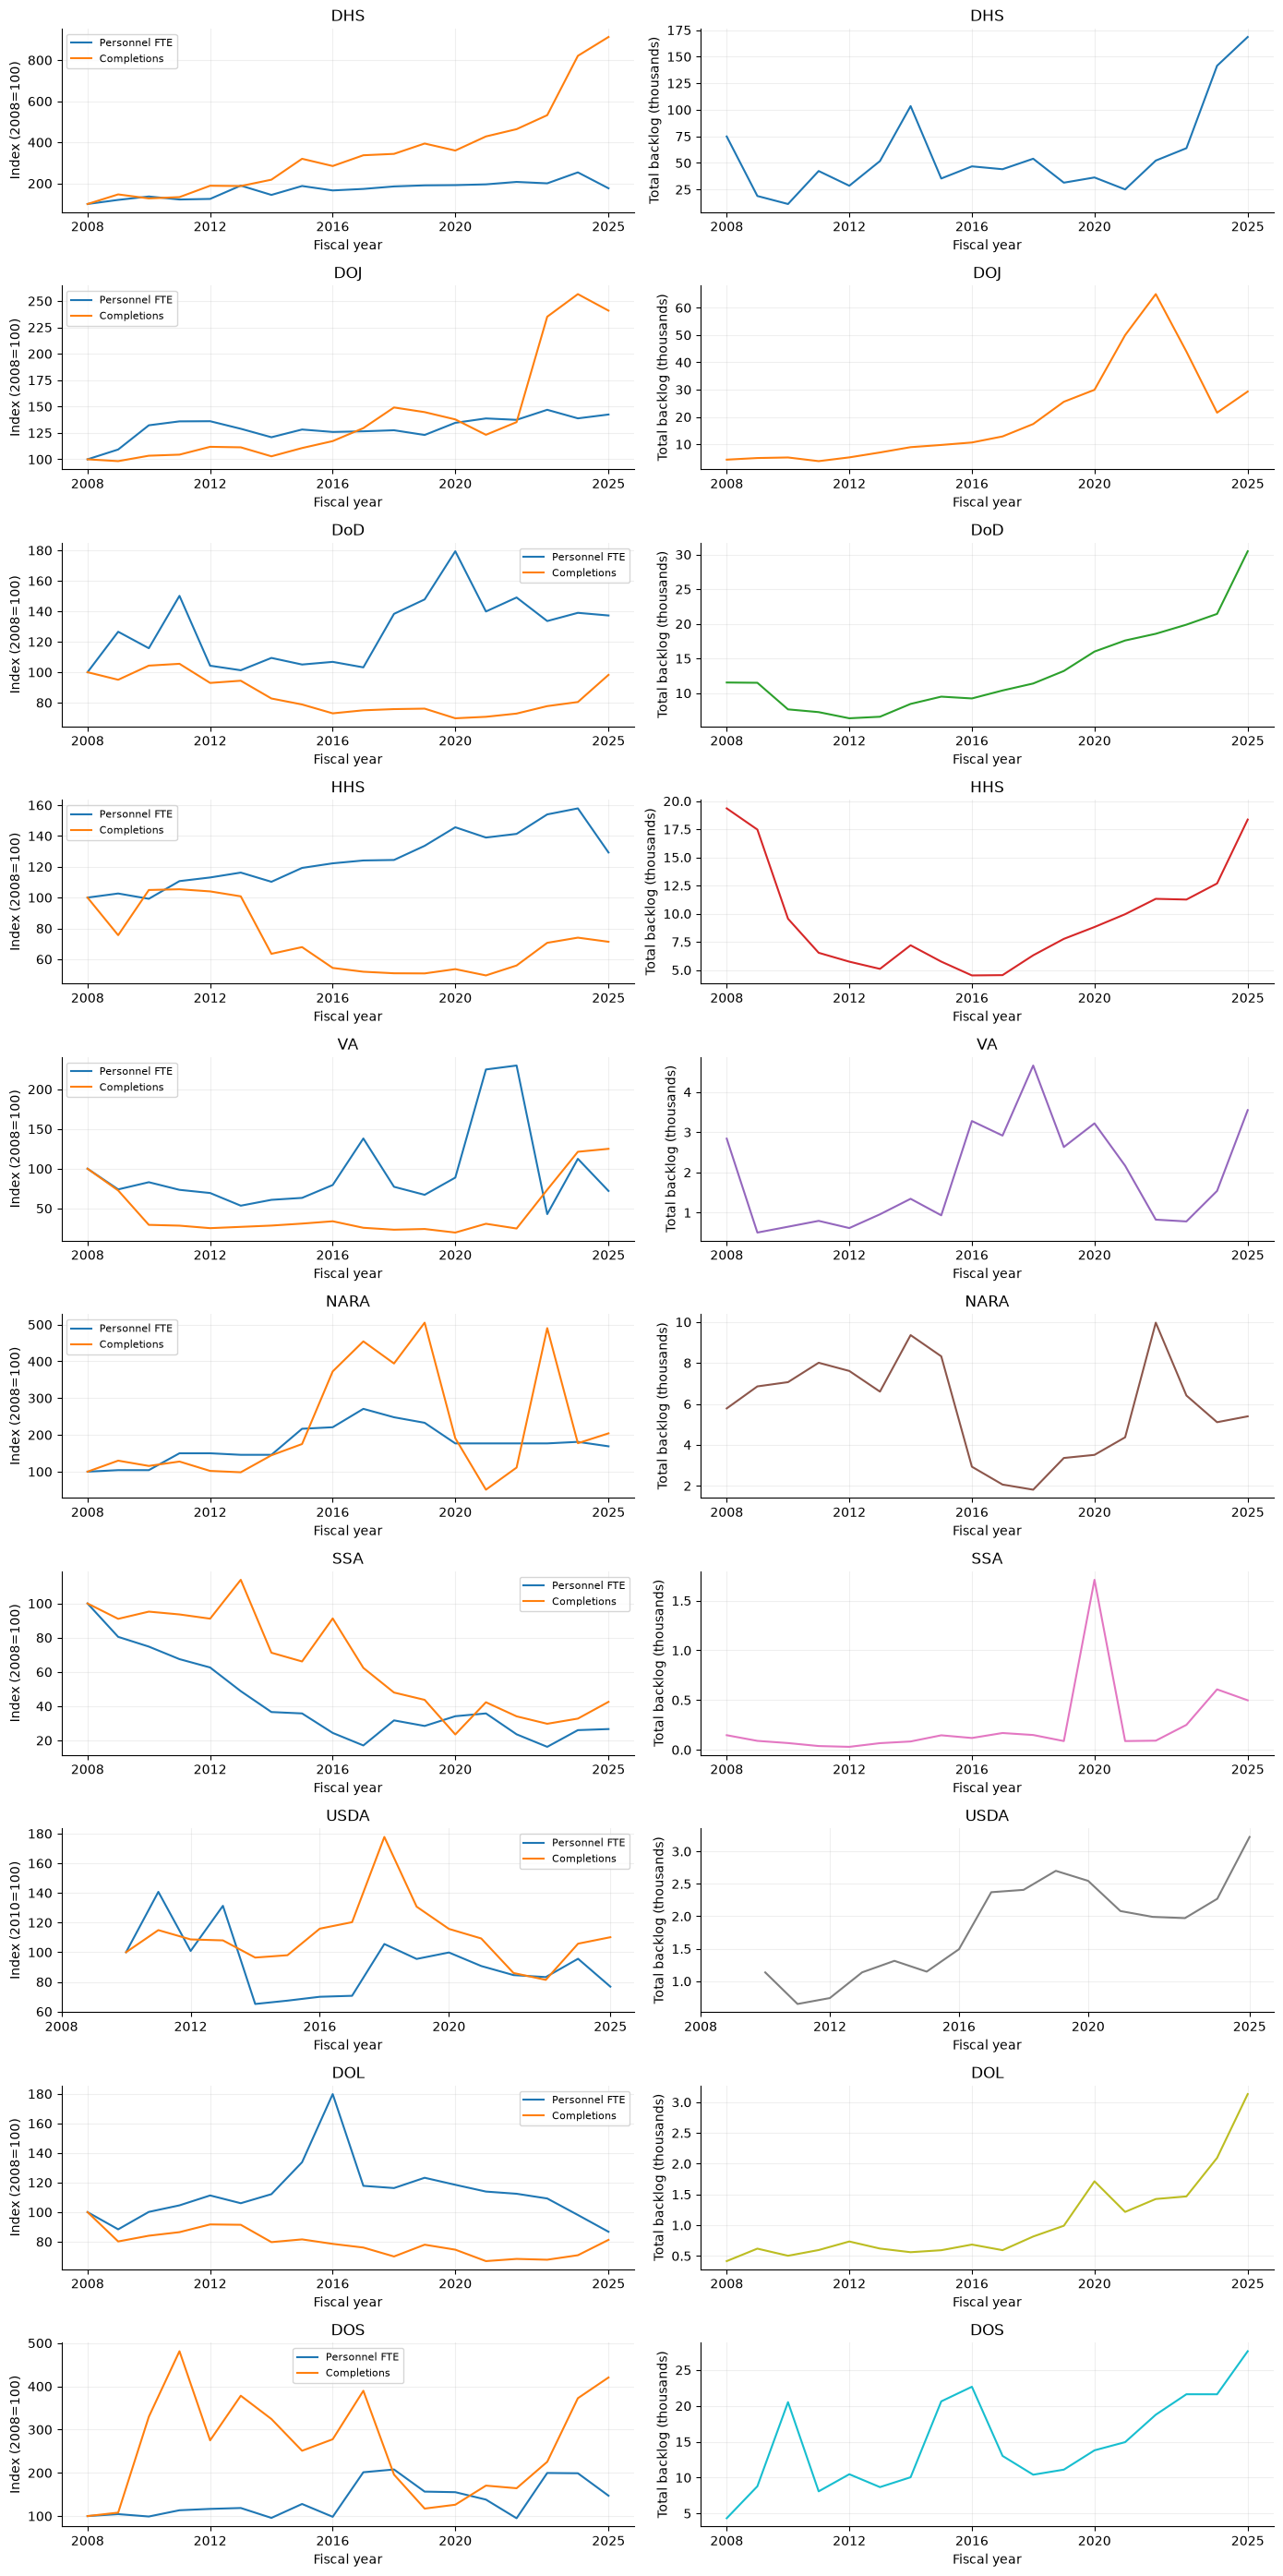

,Agency,First FY,Last FY,Initial FTE,Final FTE,Initial backlog,Final backlog
0,DHS,2008,2025,318.6,562.0,74879,168505
1,DOJ,2008,2025,388.8,553.9,4364,29308
2,DoD,2008,2025,689.6,946.4,11533,30476
3,HHS,2008,2025,257.3,332.6,19351,18360
4,VA,2008,2025,326.7,235.2,2840,3549
5,NARA,2008,2025,24.0,40.6,5781,5393
6,SSA,2008,2025,123.0,32.8,147,498
7,USDA,2010,2025,257.8,198.0,1136,3222
8,DOL,2008,2025,145.3,126.0,416,3132
9,DOS,2008,2025,132.6,195.1,4327,27619


**Trend interpretation:** Comparing each agency's endpoints, 6 agencies increase personnel; among them, 2 also reduce total backlog. Endpoints do not describe each staffing event, so the next section examines all consecutive-year changes.

In [3]:
fig, axes = plt.subplots(10, 2, figsize=(14, 28))
trend_rows = []
for row, ag in enumerate(TOP):
    q = d[d.agency.eq(ag)].dropna(subset=['fte', 'processed', 'backlog']).sort_values('year')
    if q.empty:
        continue
    first, last = (q.iloc[0], q.iloc[-1])
    for v, label in [('fte', 'Personnel FTE'), ('processed', 'Completions')]:
        if first[v] > 0:
            axes[row, 0].plot(q.year, 100 * q[v] / first[v], label=label)
    style_year(axes[row, 0], ag, f'Index ({int(first.year)}=100)')
    axes[row, 0].legend(fontsize=8)
    axes[row, 1].plot(q.year, q.backlog / 1000, color=colors[ag])
    style_year(axes[row, 1], ag, 'Total backlog (thousands)')
    trend_rows.append([ag, int(first.year), int(last.year), first.fte, last.fte, first.backlog, last.backlog])
finish(fig)
trends = pd.DataFrame(trend_rows, columns=['Agency', 'First FY', 'Last FY', 'Initial FTE', 'Final FTE', 'Initial backlog', 'Final backlog'])
table(trends, digits=1)
more_staff = trends['Final FTE'] > trends['Initial FTE']
less_backlog = trends['Final backlog'] < trends['Initial backlog']
display(Markdown(f"**Trend interpretation:** Comparing each agency's endpoints, {int(more_staff.sum())} agencies increase personnel; among them, {int((more_staff & less_backlog).sum())} also reduce total backlog. Endpoints do not describe each staffing event, so the next section examines all consecutive-year changes."))

## 2. How do staffing-increase years differ from other years?

A staffing increase means FTE exceeds the previous year's value. The comparison group includes unchanged and reduced FTE. Compare the shares with rising completions and falling total backlog, with details for each of the ten agencies. Each record represents one agency's annual change. Overall shares pool agency-years rather than averaging ten agency percentages.

,Personnel group,Agency-years,Completion increases,Completion-increase share (%),Backlog decreases,Backlog-decrease share (%)
0,Staffing increased,88,56,63.6,39,44.3
1,No staffing increase,80,36,45.0,25,31.2


,Agency,Personnel group,Agency-years,Completion increases,Completion-increase share (%),Backlog decreases,Backlog-decrease share (%)
0,DHS,Staffing increased,12,9,75.0,7,58.3
1,DHS,No staffing increase,5,4,80.0,0,0.0
2,DOJ,Staffing increased,11,7,63.6,2,18.2
3,DOJ,No staffing increase,6,3,50.0,1,16.7
4,DOL,Staffing increased,7,5,71.4,2,28.6
5,DOL,No staffing increase,10,3,30.0,3,30.0
6,DOS,Staffing increased,8,5,62.5,4,50.0
7,DOS,No staffing increase,9,6,66.7,1,11.1
8,DoD,Staffing increased,9,5,55.6,3,33.3
9,DoD,No staffing increase,8,6,75.0,2,25.0


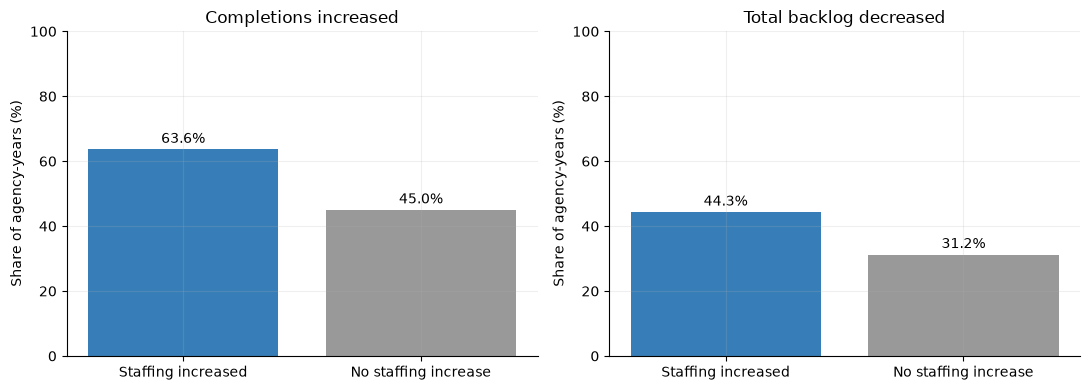

**Overall interpretation:** Relative to years without a staffing increase, staffing-increase years have a completion-increase share that is **+18.6 percentage points** different and a backlog-decrease share that is **+13.1 percentage points** different. Positive values mean the staffing-increase group has a higher share.

The groups may contain different agencies, years, and demand conditions. The difference is not a causal staffing effect.

**Agency-specific interpretation:**

- **DHS:** Backlog-decrease shares with and without a staffing increase are 58.3% and 0.0%, a difference of +58.3 percentage points.
- **DOJ:** Backlog-decrease shares with and without a staffing increase are 18.2% and 16.7%, a difference of +1.5 percentage points.
- **DoD:** Backlog-decrease shares with and without a staffing increase are 33.3% and 25.0%, a difference of +8.3 percentage points.
- **HHS:** Backlog-decrease shares with and without a staffing increase are 53.8% and 25.0%, a difference of +28.8 percentage points.
- **VA:** Backlog-decrease shares with and without a staffing increase are 44.4% and 50.0%, a difference of -5.6 percentage points.
- **NARA:** Backlog-decrease shares with and without a staffing increase are 66.7% and 36.4%, a difference of +30.3 percentage points.
- **SSA:** Backlog-decrease shares with and without a staffing increase are 60.0% and 50.0%, a difference of +10.0 percentage points.
- **USDA:** Backlog-decrease shares with and without a staffing increase are 37.5% and 42.9%, a difference of -5.4 percentage points.
- **DOL:** Backlog-decrease shares with and without a staffing increase are 28.6% and 30.0%, a difference of -1.4 percentage points.
- **DOS:** Backlog-decrease shares with and without a staffing increase are 50.0% and 11.1%, a difference of +38.9 percentage points.

In [4]:
def summarize_groups(frame, group_cols):
    rows = []
    for key, q in frame.groupby(group_cols, observed=True):
        keys = list(key) if isinstance(key, tuple) else [key]
        rows.append(keys + [len(q), int(q.delta_processed.gt(0).sum()), 100 * q.delta_processed.gt(0).mean(), int(q.delta_backlog.lt(0).sum()), 100 * q.delta_backlog.lt(0).mean()])
    return pd.DataFrame(rows, columns=group_cols + ['Agency-years', 'Completion increases', 'Completion-increase share (%)', 'Backlog decreases', 'Backlog-decrease share (%)'])
overall = summarize_groups(pairs, ['staff_group'])
table(overall, {'staff_group': 'Personnel group'}, 1)
detail = summarize_groups(pairs, ['agency', 'staff_group'])
table(detail, {'agency': 'Agency', 'staff_group': 'Personnel group'}, 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title in zip(axes, ['Completion-increase share (%)', 'Backlog-decrease share (%)'], ['Completions increased', 'Total backlog decreased']):
    ax.bar(overall.staff_group, overall[col], color=['#377eb8', '#999999'])
    ax.set(title=title, ylabel='Share of agency-years (%)', ylim=(0, 100))
    for i, v in enumerate(overall[col]):
        ax.text(i, v + 2, f'{v:.1f}%', ha='center')
finish(fig)
up = overall[overall.staff_group.eq('Staffing increased')].iloc[0]
other = overall[overall.staff_group.eq('No staffing increase')].iloc[0]
output_gap = up['Completion-increase share (%)'] - other['Completion-increase share (%)']
backlog_gap = up['Backlog-decrease share (%)'] - other['Backlog-decrease share (%)']
display(Markdown(f'**Overall interpretation:** Relative to years without a staffing increase, staffing-increase years have a completion-increase share that is **{output_gap:+.1f} percentage points** different and a backlog-decrease share that is **{backlog_gap:+.1f} percentage points** different. Positive values mean the staffing-increase group has a higher share.\n\nThe groups may contain different agencies, years, and demand conditions. The difference is not a causal staffing effect.'))
notes = []
for ag in TOP:
    q = detail[detail.agency.eq(ag)]
    if set(q.staff_group) == {'Staffing increased', 'No staffing increase'}:
        x = q.set_index('staff_group')
        gap = x.loc['Staffing increased', 'Backlog-decrease share (%)'] - x.loc['No staffing increase', 'Backlog-decrease share (%)']
        notes.append(f"- **{ag}:** Backlog-decrease shares with and without a staffing increase are {x.loc['Staffing increased', 'Backlog-decrease share (%)']:.1f}% and {x.loc['No staffing increase', 'Backlog-decrease share (%)']:.1f}%, a difference of {gap:+.1f} percentage points.")
display(Markdown('**Agency-specific interpretation:**\n\n' + '\n'.join(notes)))

## 3. What happens when request receipt growth is similar?

Group annual receipt growth into 10-percentage-point intervals. For example, [0%, 10%) includes growth of at least 0% and below 10%. Compare personnel groups within each band. Bands follow a fixed rule rather than the observed outcomes. Small groups remain visible; a band is labeled Small sample if either personnel group has fewer than five records.

Grouping makes receipt growth more similar but does not control agency size, initial backlog, or case difficulty. Bands without both personnel groups cannot provide a group comparison.

In [5]:
demand = pairs[pairs.g_received.notna()].copy()
demand['bin_low'] = (np.floor(demand.g_received * 100 / 10) * 10).astype(int)
rows = []
for low, q in demand.groupby('bin_low'):
    inc = q[q.staff_group.eq('Staffing increased')]
    not_inc = q[q.staff_group.eq('No staffing increase')]
    output_diff = 100 * (inc.delta_processed.gt(0).mean() - not_inc.delta_processed.gt(0).mean()) if len(inc) and len(not_inc) else np.nan
    backlog_diff = 100 * (inc.delta_backlog.lt(0).mean() - not_inc.delta_backlog.lt(0).mean()) if len(inc) and len(not_inc) else np.nan
    rows.append([f'[{low}%, {low + 10}%)', len(inc), len(not_inc), rate_text(inc.delta_processed, 'up'), rate_text(not_inc.delta_processed, 'up'), rate_text(inc.delta_backlog), rate_text(not_inc.delta_backlog), output_diff, backlog_diff, 'No comparison group' if not len(inc) or not len(not_inc) else 'Small sample' if min(len(inc), len(not_inc)) < 5 else 'Both groups >=5'])
demand_table = pd.DataFrame(rows, columns=['Receipt-growth band', 'Staffing-increase N', 'No-increase N', 'Staffing increased: completions up', 'No increase: completions up', 'Staffing increased: backlog down', 'No increase: backlog down', 'Completion share gap (pp)', 'Backlog share gap (pp)', 'Sample status'])
table(demand_table, digits=1)
comparable = demand_table.dropna(subset=['Backlog share gap (pp)'])
adequate = comparable[comparable['Sample status'].eq('Both groups >=5')]
display(Markdown(f"**Demand-group interpretation:** {len(comparable)} bands contain both personnel groups; the staffing-increase group has a higher backlog-decrease share in {int(comparable['Backlog share gap (pp)'].gt(0).sum())} bands, a lower share in {int(comparable['Backlog share gap (pp)'].lt(0).sum())} bands, and the same share in {int(comparable['Backlog share gap (pp)'].eq(0).sum())} bands. There are {len(adequate)} bands with at least five observations in each group; in {int(adequate['Backlog share gap (pp)'].gt(0).sum())} of these, the staffing-increase group has the higher share.\n\nThese are counts of directions across bands. Bands with different sample sizes are not averaged into a staffing-effect estimate. Small samples are unstable, and demand grouping is not causal adjustment."))

,Receipt-growth band,Staffing-increase N,No-increase N,Staffing increased: completions up,No increase: completions up,Staffing increased: backlog down,No increase: backlog down,Completion share gap (pp),Backlog share gap (pp),Sample status
0,"[-80%, -70%)",1,0,1/1(100.0%),No valid records,1/1(100.0%),No valid records,NaN,NaN,No comparison group
1,"[-70%, -60%)",1,2,0/1(0.0%),0/2(0.0%),1/1(100.0%),0/2(0.0%),0.0,100.0,Small sample
2,"[-60%, -50%)",2,0,1/2(50.0%),No valid records,1/2(50.0%),No valid records,NaN,NaN,No comparison group
3,"[-40%, -30%)",1,3,0/1(0.0%),0/3(0.0%),0/1(0.0%),1/3(33.3%),0.0,-33.3,Small sample
4,"[-30%, -20%)",3,3,0/3(0.0%),0/3(0.0%),3/3(100.0%),1/3(33.3%),0.0,66.7,Small sample
5,"[-20%, -10%)",6,12,0/6(0.0%),1/12(8.3%),4/6(66.7%),6/12(50.0%),-8.3,16.7,Both groups >=5
6,"[-10%, 0%)",13,20,5/13(38.5%),3/20(15.0%),7/13(53.8%),8/20(40.0%),23.5,13.8,Both groups >=5
7,"[0%, 10%)",28,14,22/28(78.6%),8/14(57.1%),11/28(39.3%),3/14(21.4%),21.4,17.9,Both groups >=5
8,"[10%, 20%)",15,9,14/15(93.3%),8/9(88.9%),5/15(33.3%),1/9(11.1%),4.4,22.2,Both groups >=5
9,"[20%, 30%)",9,8,4/9(44.4%),7/8(87.5%),3/9(33.3%),1/8(12.5%),-43.1,20.8,Both groups >=5


**Demand-group interpretation:** 11 bands contain both personnel groups; the staffing-increase group has a higher backlog-decrease share in 7 bands, a lower share in 3 bands, and the same share in 1 bands. There are 5 bands with at least five observations in each group; in 5 of these, the staffing-increase group has the higher share.

These are counts of directions across bands. Bands with different sample sizes are not averaged into a staffing-effect estimate. Small samples are unstable, and demand grouping is not causal adjustment.

## 4. Conclusions: what do these data support?

In [6]:
q = pairs[pairs.staff_group.eq('Staffing increased')]
paradox = pairs[pairs.delta_backlog.gt(0) & pairs.delta_backlog_per_fte.lt(0)]
display(Markdown(f"1. **Staffing-increase years:** Completions increase in {rate_text(q.delta_processed, 'up')}; total backlog falls in {rate_text(q.delta_backlog)}.\n2. **Compared with other years:** The completion-increase share differs by {output_gap:+.1f} percentage points and the backlog-decrease share by {backlog_gap:+.1f} percentage points.\n3. **Demand context:** Among {len(comparable)} comparable receipt-growth bands, {int(comparable['Backlog share gap (pp)'].gt(0).sum())} have a higher backlog-decrease share in the staffing-increase group; denominators are shown above.\n4. **Totals and per-FTE burden differ:** There are {len(paradox)} comparable records with rising total backlog but falling backlog per FTE. A denominator-driven ratio decline is not backlog reduction.\n\nThese results describe joint changes in personnel and processing performance, but cannot establish that staffing caused improvement or had no effect. Worsening backlog may trigger hiring, and initial conditions may differ between groups."))

1. **Staffing-increase years:** Completions increase in 56/88(63.6%); total backlog falls in 39/88(44.3%).
2. **Compared with other years:** The completion-increase share differs by +18.6 percentage points and the backlog-decrease share by +13.1 percentage points.
3. **Demand context:** Among 11 comparable receipt-growth bands, 7 have a higher backlog-decrease share in the staffing-increase group; denominators are shown above.
4. **Totals and per-FTE burden differ:** There are 12 comparable records with rising total backlog but falling backlog per FTE. A denominator-driven ratio decline is not backlog reduction.

These results describe joint changes in personnel and processing performance, but cannot establish that staffing caused improvement or had no effect. Worsening backlog may trigger hiring, and initial conditions may differ between groups.

## Source and execution

The only input is `component_master_no_03_06_11.csv` in this directory, from branch fa26-Tianqi, commit `c99a9a4af91d558da9a83c3c8e987f79de710f0a`. Select a Python kernel and Run All; the other notebooks need not be run first. Dependencies: pandas, NumPy, Matplotlib, and IPython. Historical reporting definitions may change; calculations retain the original reported values.